# Haul/Dump Truck: wheel-motor bearing — sensor vs camera

**Question:** can a vibration sensor and a camera each tell the condition of the bearing in an electric haul truck's wheel motor?

| | Sensor | Camera |
|---|---|---|
| Data | UODS vibration recordings (University of Ottawa bearing rig) | XJTU-DV-Rotor event camera (lab rotor rig) |
| Classes | healthy, inner race, outer race | same three |
| Tested on | 20 recordings from bearings never used for training | 9 recordings at a speed never used for training |

Ball faults are left out because the sensor data recorded them with no load, which would make "load" a shortcut. Both are lab rigs, not truck data, and they are compared by fault class only. All the code is in this notebook; run it from top to bottom.

## Step 1 — Setup

In [1]:
import json
import zipfile
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.io import loadmat
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support

# Find the project folder (the one that contains Raw_Data/ and Results/)
here = Path.cwd().resolve()
ROOT = next(p for p in (here, *here.parents) if (p / "Results").is_dir() and (p / "Raw_Data").is_dir())
RAW, RESULTS = ROOT / "Raw_Data", ROOT / "Results"


def score(actual, predicted, classes):
    """Accuracy, macro precision/recall/F1 and the confusion matrix."""
    p, r, f, _ = precision_recall_fscore_support(actual, predicted, labels=classes, zero_division=0)
    return {"accuracy": round(accuracy_score(actual, predicted), 4), "macro_precision": round(p.mean(), 4),
            "macro_recall": round(r.mean(), 4), "macro_f1": round(f.mean(), 4),
            "matrix": confusion_matrix(actual, predicted, labels=classes)}


def predict_recordings(model, x, y, recording):
    """One prediction per recording: average the model's probabilities over all its windows/frames."""
    actual, predicted = [], []
    for name in sorted(set(recording)):
        rows = recording == name
        actual.append(y[rows][0])
        predicted.append(model.classes_[np.argmax(model.predict_proba(x[rows]).mean(axis=0))])
    return actual, predicted


def forest():
    return RandomForestClassifier(n_estimators=250, max_features="sqrt", class_weight="balanced_subsample",
                                  min_samples_leaf=2, random_state=42, n_jobs=-1)


def show_matrices(panels, classes):
    fig, axes = plt.subplots(1, len(panels), figsize=(4.2 * len(panels), 3.8))
    for ax, (title, m) in zip(np.atleast_1d(axes), panels):
        ax.imshow(m, cmap="Blues", vmin=0)
        ax.set_xticks(range(len(classes)), classes, rotation=30)
        ax.set_yticks(range(len(classes)), classes)
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")
        ax.set_title(title, fontsize=10)
        for i in range(len(classes)):
            for j in range(len(classes)):
                ax.text(j, i, m[i, j], ha="center", va="center", color="white" if m[i, j] > m.max() / 2 else "black")
    fig.tight_layout()
    plt.show()


def table(rows):
    return pd.DataFrame({name: {k: v for k, v in s.items() if k != "matrix"} for name, s in rows.items()}).T


print("Project folder found:", ROOT.name)


def vibration_features(signal, rate, window, bands, include_mean):
    """Cut a signal into equal windows and compute simple time and frequency features for each."""
    n = len(signal) // window
    w = signal[: n * window].reshape(n, window)
    centered = w - w.mean(axis=1, keepdims=True)
    std = np.maximum(centered.std(axis=1), 1e-12)
    freq = np.fft.rfftfreq(window, d=1 / rate)
    power = np.abs(np.fft.rfft(centered, axis=1)) ** 2
    share = power / np.maximum(power.sum(axis=1), 1e-12)[:, None]
    columns = [
        centered.std(axis=1), np.ptp(w, axis=1),
        np.abs(centered).max(axis=1) / std,                      # crest factor
        (centered**3).mean(axis=1) / std**3,                     # skew
        (centered**4).mean(axis=1) / std**4 - 3,                 # kurtosis
        (share * freq).sum(axis=1),                              # spectral centroid
        freq[np.argmax(power[:, 1:], axis=1) + 1],               # dominant frequency
        -(share * np.log(np.maximum(share, 1e-12))).sum(axis=1), # spectral entropy
        *[share[:, (freq >= lo) & (freq < hi)].sum(axis=1) for lo, hi in bands],
    ]
    if include_mean:   # Pump only: mean and RMS of the raw signal, as in the original Pump model
        columns = [w.mean(axis=1), columns[0], np.sqrt((w**2).mean(axis=1)), *columns[1:]]
    return np.column_stack(columns).astype(np.float32)


HEIGHT, WIDTH = 480, 640          # camera resolution
GRID_H, GRID_W = 48, 64           # events are counted on a coarse 48 x 64 grid
BIN_US, END_US = 250_000, 2_000_000   # eight 250 ms images from the first 2 seconds
FRAMES = END_US // BIN_US
HOG = cv2.HOGDescriptor((64, 64), (16, 16), (8, 8), (8, 8), 9)
EVENT = np.dtype([("t", "<u4"), ("xy", "<u4")])


def event_counts(stream):
    """Read events from a .dat stream and count them per image, polarity and grid cell."""
    while True:                                   # skip the text header (lines starting with %)
        first = stream.read(1)
        if first != b"%":
            break
        stream.readline()
    stream.read(1)                                # event size byte (8)
    counts = np.zeros((FRAMES, 2, GRID_H, GRID_W), dtype=np.uint32)
    while True:
        chunk = stream.read(8 * 250_000)
        if not chunk:
            break
        ev = np.frombuffer(chunk, dtype=EVENT)
        keep = ev["t"] < END_US
        t, xy = ev["t"][keep], ev["xy"][keep]
        x, y, polarity = xy & 0x3FFF, (xy >> 14) & 0x3FFF, (xy >> 28) & 1
        index = ((((t // BIN_US) * 2 + polarity) * GRID_H + y // (HEIGHT // GRID_H)) * GRID_W
                 + x // (WIDTH // GRID_W)).astype(np.int64)
        counts += np.bincount(index, minlength=counts.size).reshape(counts.shape).astype(np.uint32)
        if ev["t"][-1] >= END_US:
            break
    return counts


def image_features(counts):
    """Turn each event image into OpenCV HOG features (one row per 250 ms image)."""
    rows = []
    for frame in counts:
        contrast = np.log1p(frame[1].astype(np.float32)) - np.log1p(frame[0].astype(np.float32))
        image = cv2.resize(contrast, (64, 64), interpolation=cv2.INTER_LINEAR)
        image = cv2.normalize(image, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
        rows.append(HOG.compute(image).ravel())
    return np.asarray(rows, dtype=np.float32)

Project folder found: capstone-week4


## Step 2 — Sensor: load the vibration recordings

20 recordings of 10 seconds from 10 bearings. Each bearing has one healthy recording and one faulty recording (bearings 1–5 inner race, 6–10 outer race). File names look like `I_3_2.mat` (inner race, bearing 3, stage 2 = faulty).

**Important fix:** every inner-race recording has a constant offset of about +50 in the signal. That is a recording artefact, not vibration, so we remove the mean of each window and do not use it as a feature. Otherwise the model could "cheat" by reading the offset.

In [2]:
TRUCK_CLASSES = ["healthy", "inner", "outer"]
CODE = {"H": "healthy", "I": "inner", "O": "outer"}
files = json.loads((RESULTS / "haul_truck.json").read_text(encoding="utf-8"))["intake"]["sensor"]["files"]

x_list, labels, bearings, recordings = [], [], [], []
for f in files:
    name = f["name"]
    signal = loadmat(RAW / "uods_vafdc" / name)[name[:-4]][:, 0]          # column 0 = accelerometer
    feats = vibration_features(signal.astype(np.float64), rate=42_000, window=4_200,
                               bands=((0, 1_000), (1_000, 2_000), (2_000, 5_000), (5_000, 10_000), (10_000, 21_000)),
                               include_mean=False)
    x_list.append(feats)
    labels += [CODE[f["class_code"]]] * len(feats)
    bearings += [f["bearing"]] * len(feats)
    recordings += [name] * len(feats)

sx, sy, sbearing, srec = np.vstack(x_list), np.array(labels), np.array(bearings), np.array(recordings)
print(f"{len(set(srec))} recordings -> {len(sx)} windows of 0.1 s, {sx.shape[1]} features each")

20 recordings -> 2000 windows of 0.1 s, 13 features each


## Step 3 — Sensor: train and test

Five rounds. Each round hides two whole bearings (one inner-race and one outer-race, with their healthy recordings) and trains on the other eight. Every recording is predicted once by a model that never saw its bearing.

In [3]:
actual, predicted, guess_actual, guess_predicted = [], [], [], []
for k in range(1, 6):
    test = np.isin(sbearing, [k, k + 5])
    model = forest().fit(sx[~test], sy[~test])
    a, p = predict_recordings(model, sx[test], sy[test], srec[test])
    actual += a
    predicted += p
    guess = DummyClassifier(strategy="most_frequent").fit(sx[~test], sy[~test])
    a, p = predict_recordings(guess, sx[test], sy[test], srec[test])
    guess_actual += a
    guess_predicted += p

sensor = score(actual, predicted, TRUCK_CLASSES)
sensor_guess = score(guess_actual, guess_predicted, TRUCK_CLASSES)
display(table({"Sensor model (20 recordings)": sensor, "Always guess one class": sensor_guess}))

,accuracy,macro_precision,macro_recall,macro_f1
Sensor model (20 recordings),0.9,0.9141,0.8667,0.8705
Always guess one class,0.5,0.1667,0.3333,0.2222


## Step 4 — Camera: turn event recordings into images

18 recordings: 3 classes × 3 camera angles × 2 speeds (1000 and 2000 rpm). Same method as the Pump: eight 250 ms event images from the first 2 seconds, described with OpenCV HOG features.

In [4]:
import re

ZIP = RAW / "xjtu_dv_rotor" / "XJTU-DV-Rotor.zip"
PATTERN = re.compile(r"^Data/(Healthy|Inner|Outer)/angle([123])_\1_(1000|2000)\.dat$")

x_list, labels, angles, speeds, recordings = [], [], [], [], []
with zipfile.ZipFile(ZIP) as archive:
    members = sorted(i.filename for i in archive.infolist() if PATTERN.match(i.filename))
    for name in members:
        cls, angle, rpm = PATTERN.match(name).groups()
        with archive.open(name) as stream:
            feats = image_features(event_counts(stream))
        x_list.append(feats)
        labels += [cls.lower()] * len(feats)
        angles += [int(angle)] * len(feats)
        speeds += [int(rpm)] * len(feats)
        recordings += [name] * len(feats)

cx, cy, cangle, cspeed, crec = (np.vstack(x_list), np.array(labels), np.array(angles), np.array(speeds), np.array(recordings))
print(f"{len(set(crec))} recordings -> {len(cx)} images, {cx.shape[1]} HOG features each")

18 recordings -> 144 images, 1764 HOG features each


## Step 5 — Camera: train and test

Main test: train on 1000 rpm, test on 2000 rpm (9 recordings). Extra check: hide each camera angle in turn (18 recordings).

In [5]:
train, test = cspeed == 1000, cspeed == 2000
model = forest().fit(cx[train], cy[train])
camera = score(*predict_recordings(model, cx[test], cy[test], crec[test]), TRUCK_CLASSES)
guess = DummyClassifier(strategy="most_frequent").fit(cx[train], cy[train])
camera_guess = score(*predict_recordings(guess, cx[test], cy[test], crec[test]), TRUCK_CLASSES)

actual, predicted = [], []
for a in (1, 2, 3):
    m = forest().fit(cx[cangle != a], cy[cangle != a])
    got = predict_recordings(m, cx[cangle == a], cy[cangle == a], crec[cangle == a])
    actual += got[0]
    predicted += got[1]
camera_angle = score(actual, predicted, TRUCK_CLASSES)

display(table({"Camera model (9 recordings at 2000 rpm)": camera, "Camera, unseen angle (18)": camera_angle,
               "Always guess one class": camera_guess}))

,accuracy,macro_precision,macro_recall,macro_f1
Camera model (9 recordings at 2000 rpm),0.4444,0.3333,0.4444,0.3556
"Camera, unseen angle (18)",0.4444,0.3000,0.4444,0.3571
Always guess one class,0.3333,0.1111,0.3333,0.1667


## Step 6 — Compare sensor and camera

,accuracy,macro_precision,macro_recall,macro_f1
Sensor: vibration,0.9000,0.9141,0.8667,0.8705
Camera: event images,0.4444,0.3333,0.4444,0.3556
Camera: unseen angle,0.4444,0.3000,0.4444,0.3571


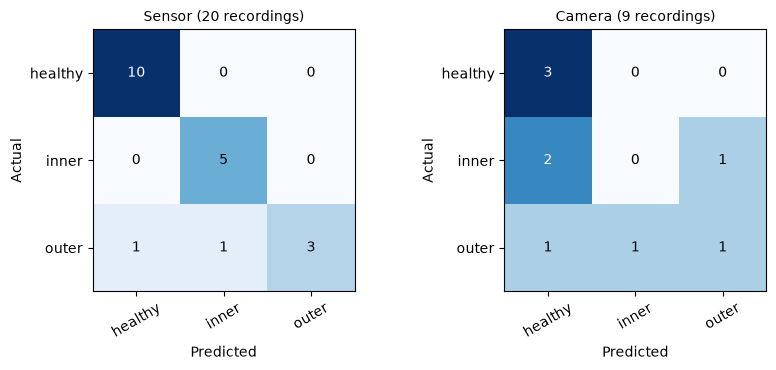

In [6]:
display(table({"Sensor: vibration": sensor, "Camera: event images": camera, "Camera: unseen angle": camera_angle}))
show_matrices([("Sensor (20 recordings)", sensor["matrix"]), ("Camera (9 recordings)", camera["matrix"])], TRUCK_CLASSES)

## Step 7 — Check against the saved results

In [7]:
saved = {}
rows = []
for label, mine, path in [
    ('Sensor', sensor, 'haul_truck.json/experiment/sensor/held_out_bearings/model'),
    ('Camera', camera, 'haul_truck.json/experiment/visual/train_1000_test_2000_rpm/model'),
    ('Camera, unseen angle', camera_angle, 'haul_truck.json/experiment/visual/held_out_camera_angle/model'),
]:
    file, *keys = path.split('/')
    node = json.loads((RESULTS / file).read_text(encoding='utf-8'))
    for key in keys:
        node = node[key]
    same = all(round(node[k], 4) == mine[k] for k in ('accuracy', 'macro_precision', 'macro_recall', 'macro_f1'))
    rows.append({'result': label, 'this notebook': mine['accuracy'], 'saved result': round(node['accuracy'], 4),
                 'same': 'yes' if same else 'NO'})
display(pd.DataFrame(rows).set_index('result'))

,this notebook,saved result,same
result,,,
Sensor,0.9000,0.9000,yes
Camera,0.4444,0.4444,yes
"Camera, unseen angle",0.4444,0.4444,yes


## What this means

- **Sensor works:** 18 of 20 recordings right (0.900) on bearings it never saw. Guessing one class gets 0.500.
- **Camera does not work well here:** 4 of 9 right (0.444), only one more than guessing (0.333), and it never recognises inner-race faults.
- **Not a winner contest.** Different lab rigs and very small test sets.
- **Limits:** lab rigs, not haul-truck data; it classifies the present condition, not when to repair.

**Data (CC BY 4.0):** UODS-VAFDC, DOI 10.17632/y2px5tg92h.1; XJTU-DV, DOI 10.5281/zenodo.17447083.